# Phase 3, step 2: complete Tier 1 (300 items)

Adds 108 items, 36 of each new question type, to the 192 offside items from step 1:

| Type | Question | Options | Balanced by |
|---|---|---|---|
| `nearest_to_carrier` | Which player (either team) is closest to the ball carrier? | nearest + 2nd–4th nearest | gap between 1st and 2nd nearest: <0.5, 0.5–1, 1–2, 2+ m (9 each); correct letter A–D (9 each) |
| `defenders_goal_side` | How many Orange players are goal-side of the ball? | 4 consecutive counts | count band ≤6, 7–8, 9–10, 11 (9 each); correct letter A–D (9 each) |
| `overload_zone` | Within 15 m of the carrier, which team has more players? | Blue / Orange / equal | outcome (12 each) |

Rules (as in step 1): answers computed from the displayed, rounded scene; exact ties dropped; no frame used twice
across the whole Tier 1 bank; fixed seed 2026. Output: `items/tier1_v0.jsonl`.

In [1]:
import sys
from pathlib import Path
from collections import Counter
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
from src.items import load_items, save_items
from src.tier1 import build_tier1_others
from src.prompts import text_prompt, image_prompt, render_scene

moments = pd.read_parquet(ROOT / "data/processed/qa/tier1_moments.parquet")   # from phase2_exploration
offside = load_items(ROOT / "items/tier1_offside_v0.jsonl")                   # from phase3_items
print(len(moments), "moments;", len(offside), "offside items")

18956 moments; 192 offside items


## 1. Build the three new types

In [2]:
others, log = build_tier1_others(moments, per_type=36, seed=2026,
                                 exclude_frames={(i.match_id, i.frame_id) for i in offside})
log

,question_type,candidates,built,selected
0,nearest_to_carrier,600,600,36
1,defenders_goal_side,600,599,36
2,overload_zone,600,600,36


## 2. Assemble and save the Tier 1 bank

In [3]:
tier1 = offside + others
assert len({i.item_id for i in tier1}) == len(tier1), "duplicate item ids"
assert len({(i.match_id, i.frame_id) for i in tier1}) == len(tier1), "a frame is used twice"
path = save_items(tier1, ROOT / "items" / "tier1_v0.jsonl")
print(f"saved {len(tier1)} items to {path.relative_to(ROOT)}")

card = pd.DataFrame([{"question_type": i.question_type, "source": i.source, "answer": i.answer} for i in tier1])
display(pd.crosstab(card.question_type, card.answer, margins=True))
display(pd.crosstab(card.question_type, card.source, margins=True))

saved 300 items to items/tier1_v0.jsonl


answer,A,B,C,D,All
question_type,,,,,
defenders_goal_side,9,9,9,9,36
nearest_to_carrier,9,9,9,9,36
offside,96,96,0,0,192
overload_zone,12,12,12,0,36
All,126,126,30,18,300


source,metrica,skillcorner,All
question_type,,,
defenders_goal_side,8,28,36
nearest_to_carrier,3,33,36
offside,27,165,192
overload_zone,7,29,36
All,45,255,300


## 3. Difficulty spread per type

In [4]:
rows = []
for i in others:
    d = i.difficulty
    if i.question_type == "nearest_to_carrier":
        rows.append({"type": i.question_type, "difficulty": "gap 1st vs 2nd nearest (m)", "value": d["gap_m"]})
    elif i.question_type == "defenders_goal_side":
        rows.append({"type": i.question_type, "difficulty": "defenders within 1 m of ball line", "value": d["near_line_1m"]})
    else:
        rows.append({"type": i.question_type, "difficulty": "players within 1 m of zone edge", "value": d["near_edge_1m"]})
pd.DataFrame(rows).groupby(["type", "difficulty"]).value.describe().round(2)

,,count,mean,std,min,25%,50%,75%,max
type,difficulty,,,,,,,,
defenders_goal_side,defenders within 1 m of ball line,36.0,0.78,0.93,0.00,0.00,0.50,1.00,3.00
nearest_to_carrier,gap 1st vs 2nd nearest (m),36.0,1.88,2.18,0.03,0.48,0.99,1.97,7.37
overload_zone,players within 1 m of zone edge,36.0,1.03,0.97,0.00,0.00,1.00,2.00,4.00


## 4. One example of each new type (coordinates format + image)

nearest_to_carrier t1-nearest-aba223e0e9 | answer: A = Orange 25 | {'gap_m': 3.9912, 'nearest_m': 3.6019, 'players_within_10m_of_carrier': 3}
You are given a snapshot of a football (soccer) match from tracking data.

Pitch: 105 m long (x axis) by 68 m wide (y axis). Origin (0, 0) is the centre spot; x runs from -52.5 to +52.5 and y from -34 to +34. Units are metres.
Blue is in possession and attacks towards +x: Blue is trying to score in the goal at x = +52.5. Orange defends that goal.

[... coordinate table ...]

Question: Which player (from either team, not counting Blue 55 itself) is closest to Blue 55, who has the ball? Measure straight-line distance between the points given.
A) Orange 25
B) Orange 10
C) Blue 8
D) Orange 7

Respond with only this JSON and nothing else:
{"answer": "<A|B|C|D>", "confidence": <integer 0-100>}


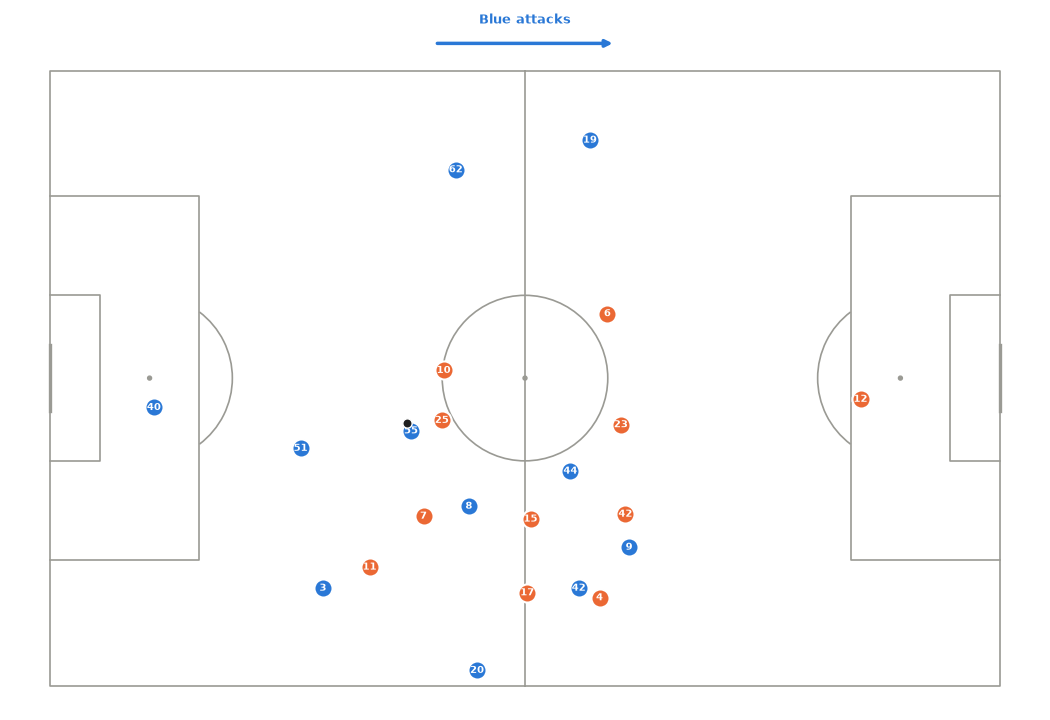

defenders_goal_side t1-goalside-0d1eb02a8c | answer: A = 9 | {'count': 9, 'near_line_1m': 0, 'closest_to_line_m': 2.78, 'ball_x': 2.09}
You are given a snapshot of a football (soccer) match from tracking data.

Pitch: 105 m long (x axis) by 68 m wide (y axis). Origin (0, 0) is the centre spot; x runs from -52.5 to +52.5 and y from -34 to +34. Units are metres.
Blue is in possession and attacks towards +x: Blue is trying to score in the goal at x = +52.5. Orange defends that goal.

[... coordinate table ...]

Question: How many Orange players are goal-side of the ball, i.e. closer than the ball to the goal Orange defends (the goal at x = +52.5)? Compare x coordinates only.
A) 9
B) 8
C) 10
D) 11

Respond with only this JSON and nothing else:
{"answer": "<A|B|C|D>", "confidence": <integer 0-100>}


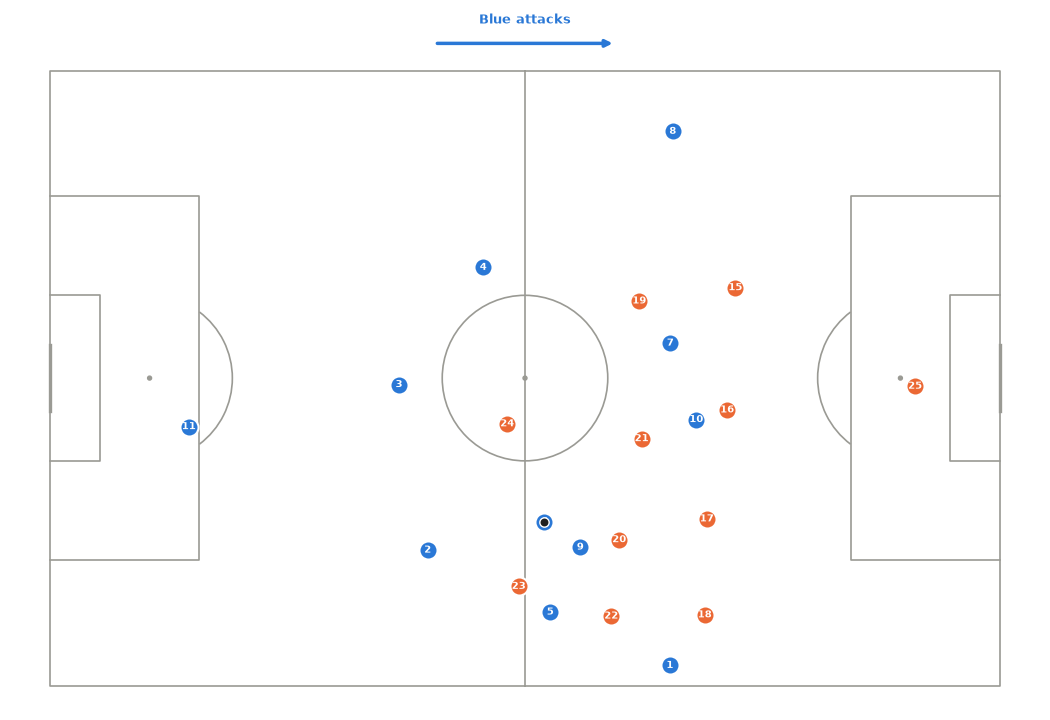

overload_zone t1-overload-4b2681fbde | answer: A = Blue has more players | {'blue_in_zone': 4, 'orange_in_zone': 2, 'abs_diff': 2, 'near_edge_1m': 0}
You are given a snapshot of a football (soccer) match from tracking data.

Pitch: 106 m long (x axis) by 68 m wide (y axis). Origin (0, 0) is the centre spot; x runs from -53 to +53 and y from -34 to +34. Units are metres.
Blue is in possession and attacks towards +x: Blue is trying to score in the goal at x = +53. Orange defends that goal.

[... coordinate table ...]

Question: Count the players of each team within 15 m (straight-line distance) of Blue 21, who has the ball. Include Blue 21 in the Blue count. Which team has more players inside that circle?
A) Blue has more players
B) Orange has more players
C) Both teams have the same number

Respond with only this JSON and nothing else:
{"answer": "<A|B|C>", "confidence": <integer 0-100>}


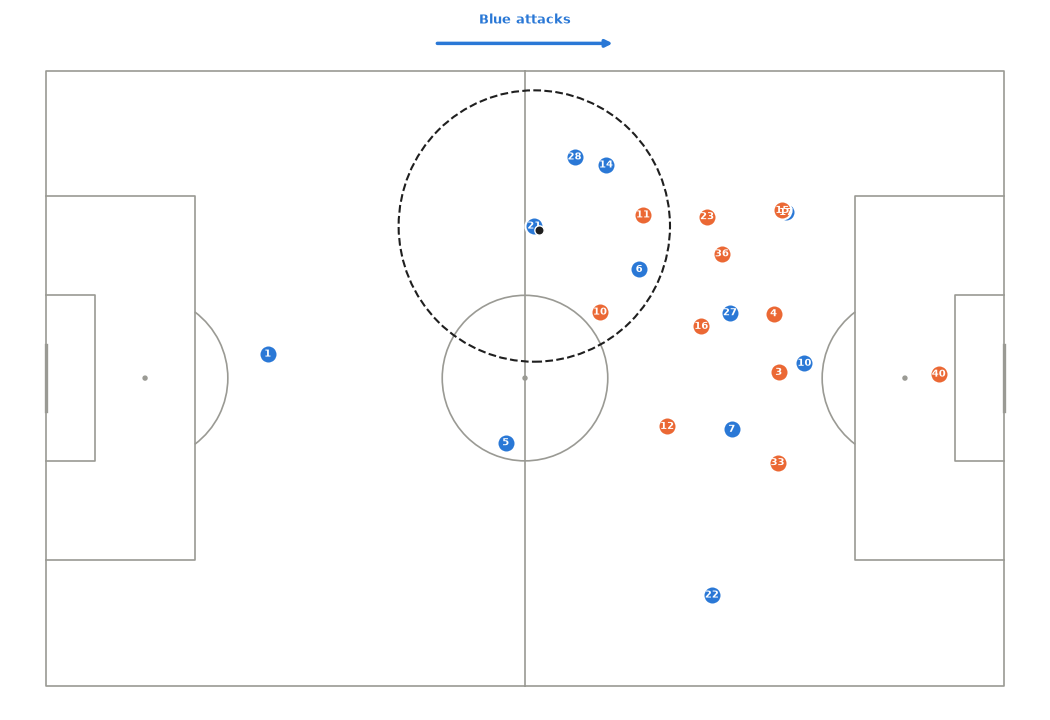

In [5]:
FIG = ROOT / "notebooks" / "figures"
for q in ("nearest_to_carrier", "defenders_goal_side", "overload_zone"):
    it = next(i for i in others if i.question_type == q)
    print("=" * 100); print(q, it.item_id, "| answer:", it.answer, "=", it.options.get(it.answer), "|", it.difficulty)
    p = text_prompt(it, "direct")
    print(p.split("Positions at this moment")[0] + "[... coordinate table ...]\n\nQuestion:" + p.split("Question:")[1])
    render_scene(it, FIG / f"example_{q}.png")
    display(Image(filename=str(FIG / f"example_{q}.png"), width=700))

## Notes (fill in)

- Letter balance per type:
- Anything surprising in the examples: